# 08 · Factores asociados a la estancia: análisis bivariado

Asociación de cada factor con la estancia en urgencias (LOS > 12 h y mediana del LOS), por separado en atención en urgencias y hospitalizados, sin modelos.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / 'src' / 'config.py').exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import pandas as pd

from src import bivariado as bv
from src import config
from src.graficos import activar_formato_tablas, aplicar_estilo, guardar_figura, titulo_hallazgo
from src.privacidad import suprimir_pequenos
from src.tablas import mostrar_tabla, tabla_medidas

aplicar_estilo()
activar_formato_tablas()
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_rows', 200)
pd.set_option('display.width', 160)

## 1. Carga y población

Tabla de características del notebook 07. Se analizan los episodios de atención en urgencias y hospitalizados válidos para tiempos, fuera del periodo de calentamiento y con LOS; las variables de historia usan solo los episodios con su ventana completa.

In [2]:
ruta = config.DATA_INTERIM / 'episodios_caracteristicas.parquet'
if not ruta.exists():
    tabla_medidas({'archivo': 'data/interim/episodios_caracteristicas.parquet', 'aviso': 'El archivo no existe.',
                   'qué hacer': 'Corre el notebook 07 para crear la tabla de características.'}, 'Tabla no disponible')
    raise SystemExit('Tabla no disponible: la celda se detiene.')

caracteristicas = pd.read_parquet(ruta)
episodios, flujo = bv.poblacion_bivariado(caracteristicas)
mostrar_tabla(suprimir_pequenos(flujo, list(flujo.columns), conservar_ceros=True),
              'Episodios por grupo después de cada filtro')

predictores = [c for c, rol in config.ROLES_CARACTERISTICAS.items() if rol == 'predictor']
sin_familia = [c for c in predictores if not any(c in variables for variables in bv.FAMILIAS.values())]
if sin_familia:
    tabla_medidas({'factores sin familia': ', '.join(sin_familia)}, 'Aviso: factores que no se analizan')
tablas = {}

**Episodios por grupo después de cada filtro**

,n_1_contacto_breve,n_2_atencion_urgencias,n_3_hospitalizado
paso,,,
Episodios de la población de análisis,216.019,192.046,34.533
Atención en urgencias y hospitalizados,0,192.046,34.533
Válidos para tiempos,0,192.046,34.533
Fuera del periodo de calentamiento,0,187.220,33.555
Con LOS,0,187.220,33.555
Con LOS e historia completa 30d,0,187.220,33.555
Con LOS e historia completa 365d,0,131.575,23.137


## 2. Asociación de cada factor con la estancia

Para cada factor y grupo: n, % con LOS > 12 h con IC de Wilson y mediana del LOS con percentiles 25 y 75, por categoría o por decil (calculado dentro de cada grupo, con sus cortes en la tabla). Hora, día de la semana, edad, sexo y hospitalización previa solo tienen tabla: su gráfico está en el notebook 04.

### 2.1 Calendario

**hora: % con LOS > 12 h y LOS por categoría y grupo**

desde  hasta       n n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h mediana_h  p25_h  p75_h
grupo                categoria                                                                                                  
2_atencion_urgencias 0            NaN    NaN   2.999       878        29,3           27,7           30,9      5,98   0,44  14,39
                     1            NaN    NaN   2.073       689        33,2           31,2           35,3         6   0,77  16,24
                     2            NaN    NaN   1.813       637        35,1           33,0           37,4      6,78   0,73  15,63
                     3            NaN    NaN   1.615       583        36,1           33,8           38,5      8,20   0,43  15,90
                     4            NaN    NaN   1.629       607        37,3           35,0           39,6      8,14   0,56  15,34
                     5            NaN    NaN   2.536       854        33,7           31,9           35,5      8,55   0,84  14,41
                     6            NaN    NaN   5.133     1.672        32,6           31,3           33,9      8,52   1,41  13,78
                     7            NaN    NaN   9.706     2.856        29,4           28,5           30,3      7,90   0,97  12,79
                     8            NaN    NaN  12.159     3.166        26,0           25,3           26,8      7,28   0,67  12,23
                     9            NaN    NaN  13.822     3.469        25,1           24,4           25,8      7,33   0,48  12,04
                     10           NaN    NaN  14.309     3.799        26,6           25,8           27,3      7,23   0,36  12,67
                     11           NaN    NaN  14.172     3.768        26,6           25,9           27,3      6,87   0,28  12,67
                     12           NaN    NaN  11.689     3.231        27,6           26,8           28,5      6,62   0,32  12,87
                     13           NaN    NaN  11.160     3.178        28,5           27,6           29,3      6,80   0,46  13,52
                     14           NaN    NaN  11.463     3.255        28,4           27,6           29,2      6,65   0,38  14,04
                     15           NaN    NaN  11.702     3.292        28,1           27,3           28,9      6,47   0,28  13,79
                     16           NaN    NaN  10.283     3.042        29,6           28,7           30,5      6,62   0,30  13,58
                     17           NaN    NaN   9.403     2.704        28,8           27,9           29,7      6,21   0,38  12,77
                     18           NaN    NaN   8.933     2.222        24,9           24,0           25,8      5,88   0,45  11,97
                     19           NaN    NaN   6.776     1.562        23,1           22,1           24,1      5,67   0,51  11,39
                     20           NaN    NaN   7.378     1.564        21,2           20,3           22,1      5,55   0,50  10,58
                     21           NaN    NaN   6.542     1.333        20,4           19,4           21,4      5,18   0,46  10,08
                     22           NaN    NaN   5.584     1.263        22,6           21,5           23,7      6,04   0,50  10,25
                     23           NaN    NaN   4.341     1.119        25,8           24,5           27,1      6,18   0,55  12,49
3_hospitalizado      0            NaN    NaN     597       367        61,5           57,5           65,3     17,40   4,32  40,72
                     1            NaN    NaN     528       305        57,8           53,5           61,9     15,83   3,89  24,03
                     2            NaN    NaN     466       272        58,4           53,8           62,8     15,18   3,27  27,81
                     3            NaN    NaN     431       247        57,3           52,6           61,9     13,89   3,61  36,77
                     4            NaN    NaN     427       264        61,8           57,1           66,3     16,35   4,83  36,56
                     5           

**dia_semana: % con LOS > 12 h y LOS por categoría y grupo**

desde  hasta       n n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h mediana_h p25_h  p75_h
grupo                categoria                                                                                                 
2_atencion_urgencias Lun          NaN    NaN  30.428     8.063        26,5           26,0           27,0      6,65  0,42  12,52
                     Mar          NaN    NaN  28.949     7.961        27,5           27,0           28,0      6,93  0,36  12,88
                     Mié          NaN    NaN  28.007     7.585        27,1           26,6           27,6      6,71  0,35  12,78
                     Jue          NaN    NaN  28.005     8.066        28,8           28,3           29,3      6,94  0,43  13,35
                     Vie          NaN    NaN  27.317     7.381        27,0           26,5           27,6      6,83  0,41  12,72
                     Sáb          NaN    NaN  23.219     6.096        26,2           25,7           26,8      6,48  0,54  12,44
                     Dom          NaN    NaN  21.295     5.591        26,2           25,7           26,9      6,33  0,63  12,53
3_hospitalizado      Lun          NaN    NaN   5.091     3.601        70,7           69,5           72,0     27,01  9,83  48,95
                     Mar          NaN    NaN   5.122     3.536        69,0           67,8           70,3     25,56  9,15  42,73
                     Mié          NaN    NaN   4.950     3.387        68,4           67,1           69,7     24,05  8,93  46,03
                     Jue          NaN    NaN   5.087     3.490        68,6           67,3           69,9     23,79     9  38,80
                     Vie          NaN    NaN   5.163     3.603        69,8           68,5           71,0     24,10  9,25  38,97
                     Sáb          NaN    NaN   4.199     2.780        66,2           64,8           67,6     20,84  8,14  42,91
                     Dom          NaN    NaN   3.943     2.446        62,0           60,5           63,5     20,78  6,43  46,59

**mes: % con LOS > 12 h y LOS por categoría y grupo**

desde  hasta       n n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h mediana_h  p25_h  p75_h
grupo                categoria                                                                                                  
2_atencion_urgencias 1            NaN    NaN  14.782     3.949        26,7           26,0           27,4      6,95   0,60  12,54
                     2            NaN    NaN  17.214     4.788        27,8           27,1           28,5      6,51   0,60  13,22
                     3            NaN    NaN  19.603     5.612        28,6           28,0           29,3      6,86   0,53  13,40
                     4            NaN    NaN  14.994     4.051        27,0           26,3           27,7      6,64   0,51  12,64
                     5            NaN    NaN  16.202     4.527        27,9           27,3           28,6      6,71   0,38  13,01
                     6            NaN    NaN  15.640     4.230        27,1           26,4           27,8      6,30   0,33  12,78
                     7            NaN    NaN  15.555     4.063        26,1           25,4           26,8      6,85   0,50  12,36
                     8            NaN    NaN  15.648     4.059        25,9           25,3           26,6      6,60   0,37  12,34
                     9            NaN    NaN  15.138     3.925        25,9           25,2           26,6      6,78   0,39  12,34
                     10           NaN    NaN  14.686     3.967        27,0           26,3           27,7      6,90   0,57  12,74
                     11           NaN    NaN  14.304     4.050        28,3           27,6           29,1      6,87   0,37  13,36
                     12           NaN    NaN  13.454     3.522        26,2           25,4           26,9      6,59   0,47  12,41
3_hospitalizado      1            NaN    NaN   2.777     1.886        67,9           66,2           69,6     23,62   8,71  45,27
                     2            NaN    NaN   3.148     2.178        69,2           67,5           70,8     25,48   8,94  52,67
                     3            NaN    NaN   3.285     2.217        67,5           65,9           69,1     22,76   8,34  45,85
                     4            NaN    NaN   2.747     1.911        69,6           67,8           71,3     23,63   9,57  37,50
                     5            NaN    NaN   2.724     1.937        71,1           69,4           72,8     24,90  10,26  40,26
                     6            NaN    NaN   2.631     1.753        66,6           64,8           68,4     23,52   8,23  42,52
                     7            NaN    NaN   2.900     1.968        67,9           66,1           69,5     22,92   8,80  37,85
                     8            NaN    NaN   2.951     2.026        68,7           67,0           70,3     24,05   9,38  42,48
                     9            NaN    NaN   2.671     1.833        68,6           66,8           70,4     24,55   8,60  47,41
                     10           NaN    NaN   2.652     1.808        68,2           66,4           69,9     25,19   8,32  42,32
                     11           NaN    NaN   2.370     1.622        68,4           66,5           70,3     27,23   8,64  52,17
                     12           NaN    NaN   2.699     1.704        63,1           61,3           64,9     19,64   7,64  38,08

... (4 outputs left out)

**festivo: % con LOS > 12 h y LOS por categoría y grupo**

desde  hasta        n n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h mediana_h p25_h  p75_h
grupo                categoria                                                                                                  
2_atencion_urgencias No           NaN    NaN  179.507    48.865        27,2           27,0           27,4      6,74  0,45  12,80
                     Sí           NaN    NaN    7.713     1.878        24,4           23,4           25,3      6,07  0,56  11,79
3_hospitalizado      No           NaN    NaN   32.192    21.960        68,2           67,7           68,7     24,01  8,79  43,33
                     Sí           NaN    NaN    1.363       883        64,8           62,2           67,3     23,95  7,21  46,18

**franja: % con LOS > 12 h y LOS por categoría y grupo**

desde  hasta       n n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h mediana_h  p25_h  p75_h
grupo                categoria                                                                                                  
2_atencion_urgencias 00–06        NaN    NaN  12.665     4.248        33,5           32,7           34,4      6,73   0,64  15,10
                     06–12        NaN    NaN  69.301    18.730        27,0           26,7           27,4      7,37   0,56  12,61
                     12–18        NaN    NaN  65.700    18.702        28,5           28,1           28,8      6,58   0,35  13,32
                     18–24        NaN    NaN  39.554     9.063        22,9           22,5           23,3      5,71   0,49  11,24
3_hospitalizado      00–06        NaN    NaN   3.111     1.889        60,7           59,0           62,4     16,35   4,42  36,93
                     06–12        NaN    NaN  12.729     9.016        70,8           70,0           71,6     28,14  10,37  40,45
                     12–18        NaN    NaN  10.842     7.423        68,5           67,6           69,3     27,26   9,02  50,55
                     18–24        NaN    NaN   6.873     4.515        65,7           64,6           66,8     21,59   6,35  43,68

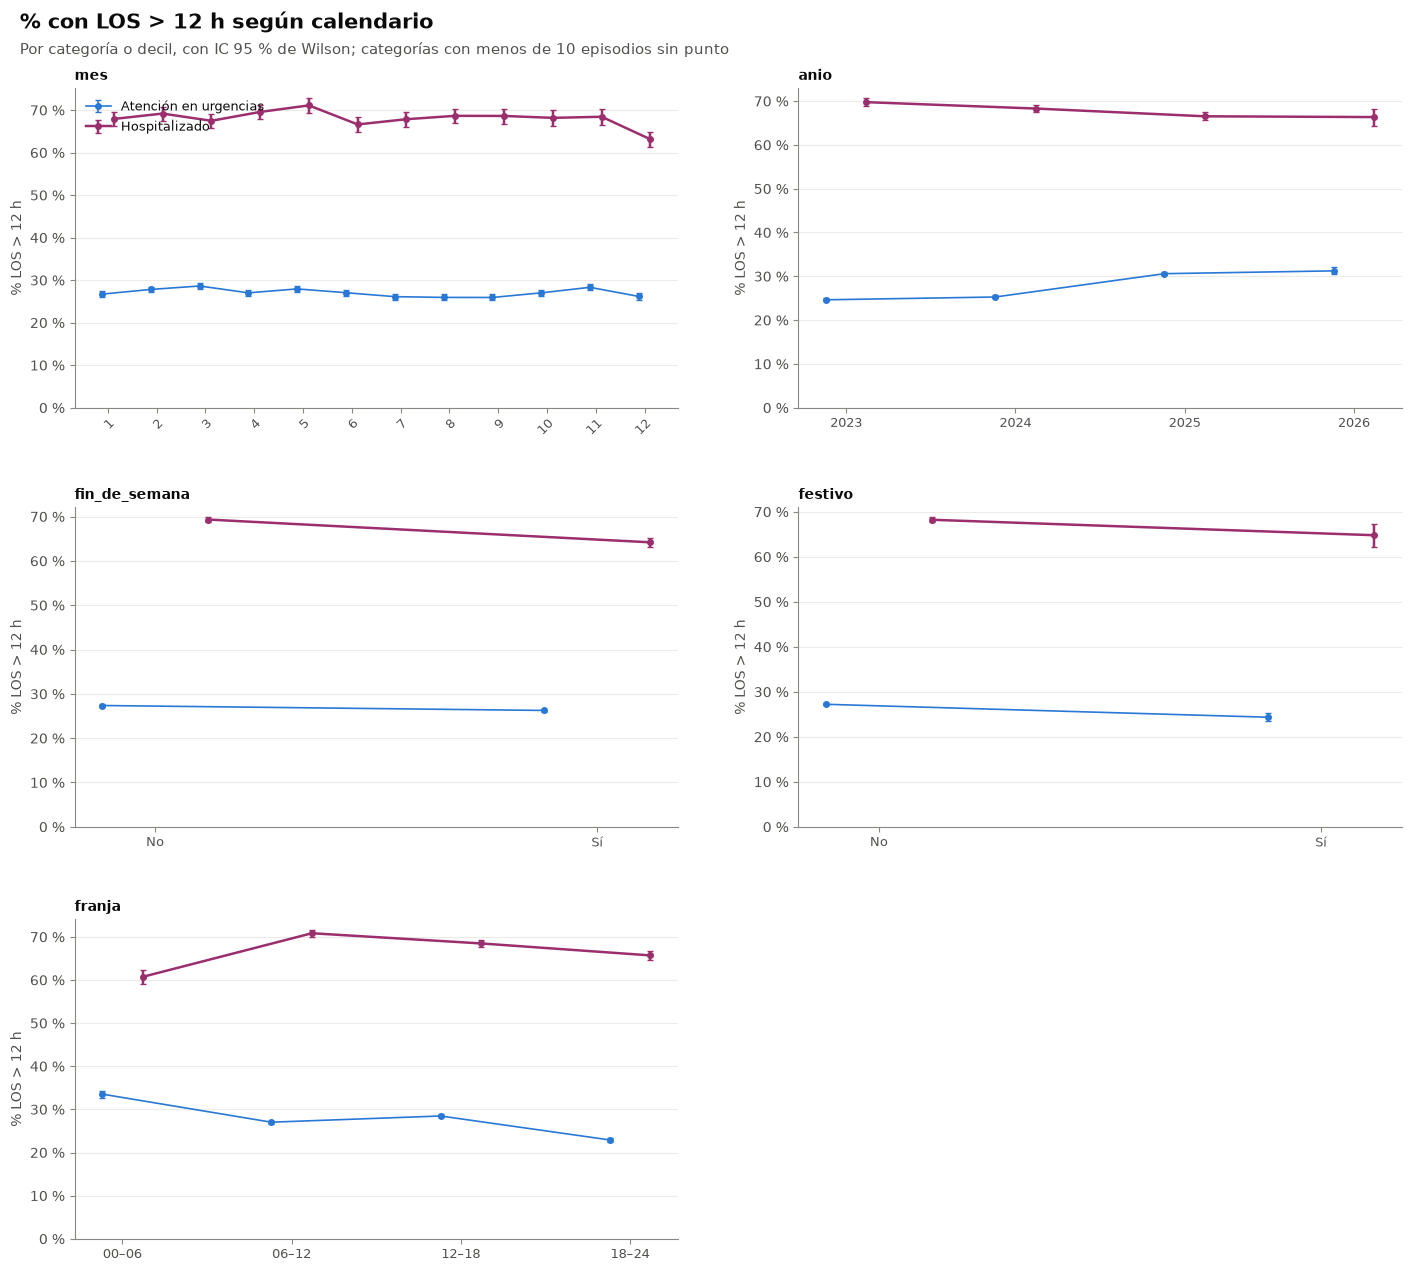

In [3]:
tablas.update(bv.mostrar_familia(episodios, 'calendario', '08_calendario'))

### 2.2 Paciente

In [4]:
tablas.update(bv.mostrar_familia(episodios, 'paciente', '08_paciente'))

**sexo: % con LOS > 12 h y LOS por categoría y grupo**

desde  hasta        n n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h  mediana_h      p25_h      p75_h
grupo                categoria                                                                                                                  
2_atencion_urgencias femenino           NaN    NaN  108.416    29.455        27,2           26,9           27,4       6,99       0,70      12,75
                     masculino          NaN    NaN   78.802    21.287        27,0           26,7           27,3       6,26       0,29      12,78
                     otro_o_sin_dato    NaN    NaN      <10       <10   suprimido      suprimido      suprimido  suprimido  suprimido  suprimido
3_hospitalizado      femenino           NaN    NaN   19.099    13.257        69,4           68,8           70,1      24,44       9,41      43,27
                     masculino          NaN    NaN   14.456     9.586        66,3           65,5           67,1      23,44       7,74      43,86

**edad_llegada: % con LOS > 12 h y LOS por categoría y grupo**

desde hasta       n n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h mediana_h  p25_h  p75_h
grupo                categoria                                                                                                
2_atencion_urgencias D1            0     4  18.942     2.892        15,3           14,8           15,8      0,48   0,11   7,82
                     D2            4    12  19.062     3.841        20,1           19,6           20,7      2,59   0,14   9,93
                     D3           12    20  20.733     5.049        24,4           23,8           24,9      5,46   0,29  11,73
                     D4           20    24  17.186     4.289        25,0           24,3           25,6      6,57   0,82  11,99
                     D5           24    29  19.390     5.131        26,5           25,9           27,1      6,87   1,09  12,47
                     D6           29    35  17.832     4.884        27,4           26,7           28,1      7,22   1,40  12,75
                     D7           35    44  18.857     5.611        29,8           29,1           30,4      7,79   1,56  13,58
                     D8           44    56  19.163     5.948        31,0           30,4           31,7      8,04   1,96  14,13
                     D9           56    68  17.349     5.821        33,5           32,9           34,3      8,51   2,61  15,12
                     D10          68   107  18.706     7.277        38,9           38,2           39,6      9,54   4,52  18,63
3_hospitalizado      D1            0     6   3.500     1.624        46,4           44,8           48,1     10,61   5,66  28,50
                     D2            6    16   3.296     2.053        62,3           60,6           63,9     17,77   7,17  33,15
                     D3           16    22   3.767     2.556        67,8           66,3           69,3     20,87   9,14  35,03
                     D4           22    27   3.318     2.340        70,5           69,0           72,0     23,14   9,90  36,88
                     D5           27    33   3.024     2.219        73,4           71,8           74,9     25,26  11,32  42,32
                     D6           33    42   3.249     2.433        74,9           73,4           76,3     27,98  11,94  50,67
                     D7           42    54   3.427     2.618        76,4           74,9           77,8     30,55  12,76  54,41
                     D8           54    64   3.280     2.344        71,5           69,9           73,0     29,10   9,93  54,14
                     D9           64    75   3.371     2.359        70,0           68,4           71,5     28,19   9,02  54,34
                     D10          75   108   3.323     2.297        69,1           67,5           70,7     28,19   7,99  53,27

**pediatria: % con LOS > 12 h y LOS por categoría y grupo**

desde  hasta        n n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h mediana_h  p25_h  p75_h
grupo                categoria                                                                                                   
2_atencion_urgencias No           NaN    NaN  139.346    41.626        29,9           29,6           30,1      7,66   1,58  13,69
                     Sí           NaN    NaN   47.874     9.117        19,0           18,7           19,4      1,62   0,13   9,47
3_hospitalizado      No           NaN    NaN   26.188    18.825        71,9           71,3           72,4     26,87  10,35  48,93
                     Sí           NaN    NaN    7.367     4.018        54,5           53,4           55,7     13,97   6,26  30,84

**grupo_edad: % con LOS > 12 h y LOS por categoría y grupo**

desde  hasta       n n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h mediana_h  p25_h  p75_h
grupo                categoria                                                                                                  
2_atencion_urgencias <1           NaN    NaN   4.472       689        15,4           14,4           16,5      0,49   0,12   7,44
                     1-4          NaN    NaN  14.470     2.203        15,2           14,7           15,8      0,48   0,11   7,94
                     5-17         NaN    NaN  28.932     6.225        21,5           21,1           22,0      3,43   0,15  10,53
                     18-44        NaN    NaN  84.128    22.580        26,8           26,5           27,1      6,98   0,98  12,62
                     45-64        NaN    NaN  31.145     9.887        31,8           31,2           32,3      8,16   2,03  14,34
                     65-79        NaN    NaN  16.892     6.170        36,5           35,8           37,3      9,13   4,07  16,86
                     80+          NaN    NaN   7.181     2.989        41,6           40,5           42,8     10,02   4,78  21,10
3_hospitalizado      <1           NaN    NaN     947       319        33,7           30,8           36,8      7,62      5  19,29
                     1-4          NaN    NaN   1.933       933        48,3           46,0           50,5     11,20   5,93  29,40
                     5-17         NaN    NaN   4.487     2.766        61,6           60,2           63,1     17,40   7,08  32,85
                     18-44        NaN    NaN  13.393     9.684        72,3           71,5           73,1     24,96  10,80  40,85
                     45-64        NaN    NaN   6.101     4.485        73,5           72,4           74,6     29,77  11,10  54,42
                     65-79        NaN    NaN   4.415     3.092        70,0           68,7           71,4     28,29   8,88  54,06
                     80+          NaN    NaN   2.279     1.564        68,6           66,7           70,5     27,98   7,85  53,29

### 2.3 Historia previa

Solo episodios con la ventana de historia de la variable completa (30 o 365 días).

**hosp_previa_30d: % con LOS > 12 h y LOS por categoría y grupo**

desde  hasta        n n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h mediana_h p25_h  p75_h
grupo                categoria                                                                                                  
2_atencion_urgencias No           NaN    NaN  184.220    49.864        27,1           26,9           27,3      6,70  0,45  12,75
                     Sí           NaN    NaN    3.000       879        29,3           27,7           30,9      7,11  0,40  13,63
3_hospitalizado      No           NaN    NaN   32.900    22.406        68,1           67,6           68,6     23,96  8,73  43,33
                     Sí           NaN    NaN      655       437        66,7           63,0           70,2     26,14  8,68  52,40

**n_episodios_previos_30d: % con LOS > 12 h y LOS por categoría y grupo**

desde  hasta        n n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h mediana_h p25_h  p75_h
grupo                categoria                                                                                                  
2_atencion_urgencias 0            NaN    NaN  157.124    41.155        26,2           26,0           26,4      6,47  0,36  12,43
                     1            NaN    NaN   23.623     7.611        32,2           31,6           32,8      7,94  2,47  14,78
                     2            NaN    NaN    4.791     1.499        31,3           30,0           32,6      7,81  3,57  14,58
                     3 o más      NaN    NaN    1.682       478        28,4           26,3           30,6      7,23  3,69  13,27
3_hospitalizado      0            NaN    NaN   26.101    17.677        67,7           67,2           68,3     24,34  8,53  44,79
                     1            NaN    NaN    5.897     4.096        69,5           68,3           70,6     23,12  9,52  40,95
                     2            NaN    NaN    1.281       881        68,8           66,2           71,2     20,63  9,91  36,78
                     3 o más      NaN    NaN      276       189        68,5           62,8           73,7     23,33  9,78  37,75

**n_episodios_previos_365d: % con LOS > 12 h y LOS por categoría y grupo**

desde  hasta       n n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h mediana_h  p25_h  p75_h
grupo                categoria                                                                                                  
2_atencion_urgencias 0            NaN    NaN  75.436    20.078        26,6           26,3           26,9      6,36   0,29  12,61
                     1            NaN    NaN  26.665     8.079        30,3           29,8           30,9      7,68   1,42  13,86
                     2            NaN    NaN  12.944     3.855        29,8           29,0           30,6      7,61   1,70  13,68
                     3 o más      NaN    NaN  16.530     5.025        30,4           29,7           31,1      7,80   2,39  13,96
3_hospitalizado      0            NaN    NaN  12.273     7.990        65,1           64,2           65,9     22,80   7,37  43,63
                     1            NaN    NaN   5.149     3.556        69,1           67,8           70,3     23,94   9,42  46,11
                     2            NaN    NaN   2.529     1.781        70,4           68,6           72,2     26,49   9,75  50,50
                     3 o más      NaN    NaN   3.186     2.249        70,6           69,0           72,2     25,18  10,13  48,35

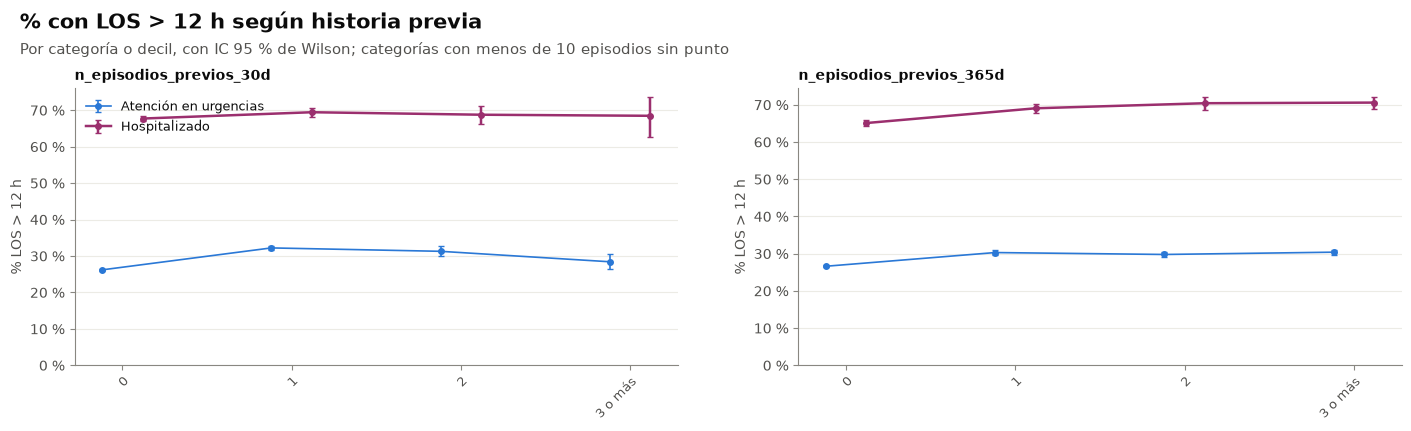

In [5]:
tablas.update(bv.mostrar_familia(episodios, 'historia previa', '08_historia_previa'))

### 2.4 Cola en urgencias

**urg_atencion_presentes_llegada: % con LOS > 12 h y LOS por categoría y grupo**

desde hasta       n n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h mediana_h p25_h  p75_h
grupo                categoria                                                                                               
2_atencion_urgencias D1           27   102  19.084     5.005        26,2           25,6           26,9      6,55  0,69  12,34
                     D2          102   116  19.273     4.987        25,9           25,3           26,5      6,66  0,54  12,28
                     D3          116   126  19.046     5.009        26,3           25,7           26,9      6,55  0,53  12,44
                     D4          126   135  19.480     5.115        26,3           25,6           26,9      6,57  0,47  12,41
                     D5          135   143  18.090     4.822        26,7           26,0           27,3      6,57  0,41  12,60
                     D6          143   151  17.560     4.797        27,3           26,7           28,0      6,88  0,45  12,92
                     D7          151   160  18.622     4.952        26,6           26,0           27,2      6,71  0,41  12,64
                     D8          160   171  19.472     5.384        27,6           27,0           28,3      6,67  0,35  12,98
                     D9          171   186  18.593     5.386        29,0           28,3           29,6      6,96  0,36  13,50
                     D10         186   262  18.000     5.286        29,4           28,7           30,0      7,01  0,33  13,70
3_hospitalizado      D1           27    98   3.464     2.251        65,0           63,4           66,5     17,12  8,38  37,58
                     D2           98   112   3.302     2.250        68,1           66,5           69,7     20,67  8,56  38,33
                     D3          112   122   3.359     2.198        65,4           63,8           67,0     21,42  8,07  39,74
                     D4          122   131   3.615     2.517        69,6           68,1           71,1     24,14  9,28  42,17
                     D5          131   139   3.201     2.258        70,5           68,9           72,1     25,31  9,66  45,02
                     D6          139   148   3.418     2.368        69,3           67,7           70,8     26,20  8,88  47,37
                     D7          148   157   3.237     2.208        68,2           66,6           69,8     25,15  8,38  45,76
                     D8          157   167   3.255     2.231        68,5           66,9           70,1     26,40  8,62  48,91
                     D9          167   182   3.389     2.357        69,5           68,0           71,1     25,88  9,27  48,55
                     D10         182   261   3.315     2.205        66,5           64,9           68,1     25,76  8,67  50,78

**urg_atencion_presentes_llegada_pct_trimestre: % con LOS > 12 h y LOS por categoría y grupo**

desde  hasta       n n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h mediana_h p25_h  p75_h
grupo                categoria                                                                                                 
2_atencion_urgencias D1             0  14,86  18.804     5.278        28,1           27,4           28,7      7,07  0,76  12,91
                     D2         14,86  27,36  18.724     5.130        27,4           26,8           28,0      7,04  0,60  12,69
                     D3         27,36  38,46  18.700     4.994        26,7           26,1           27,3      6,88  0,60  12,66
                     D4         38,46  49,40  18.793     5.006        26,6           26,0           27,3      6,65  0,55  12,65
                     D5         49,40  59,07  18.629     4.943        26,5           25,9           27,2      6,72  0,43  12,53
                     D6         59,07  68,48  18.748     4.930        26,3           25,7           26,9      6,69  0,44  12,54
                     D7         68,48  76,99  18.872     5.143        27,2           26,6           27,9      6,55  0,34  12,92
                     D8         76,99  85,01  18.592     5.137        27,6           27,0           28,3      6,54  0,33  12,90
                     D9         85,01  92,82  18.669     4.953        26,5           25,9           27,2      6,48  0,32  12,60
                     D10        92,82    100  18.689     5.229        28,0           27,3           28,6      6,57  0,30  13,24
3_hospitalizado      D1             0     12   3.370     2.142        63,6           61,9           65,2     16,39  8,06  37,71
                     D2            12  23,51   3.362     2.352        70,0           68,4           71,5     21,23  9,42  40,63
                     D3         23,51  34,07   3.347     2.251        67,2           65,7           68,8     20,49  8,20  39,31
                     D4         34,07  44,97   3.353     2.195        65,5           63,8           67,0     21,81  7,64  41,53
                     D5         44,97  54,77   3.353     2.345        69,9           68,4           71,5     24,33  9,04  43,15
                     D6         54,77  64,51   3.356     2.318        69,1           67,5           70,6     24,86     9  42,69
                     D7         64,51  73,91   3.361     2.311        68,8           67,2           70,3     26,06  9,05  46,40
                     D8         73,91  82,73   3.347     2.299        68,7           67,1           70,2     25,94  8,77  49,15
                     D9         82,73  91,39   3.396     2.351        69,2           67,7           70,8        27     9  49,53
                     D10        91,39    100   3.310     2.279        68,8           67,2           70,4     26,25  9,06  49,75

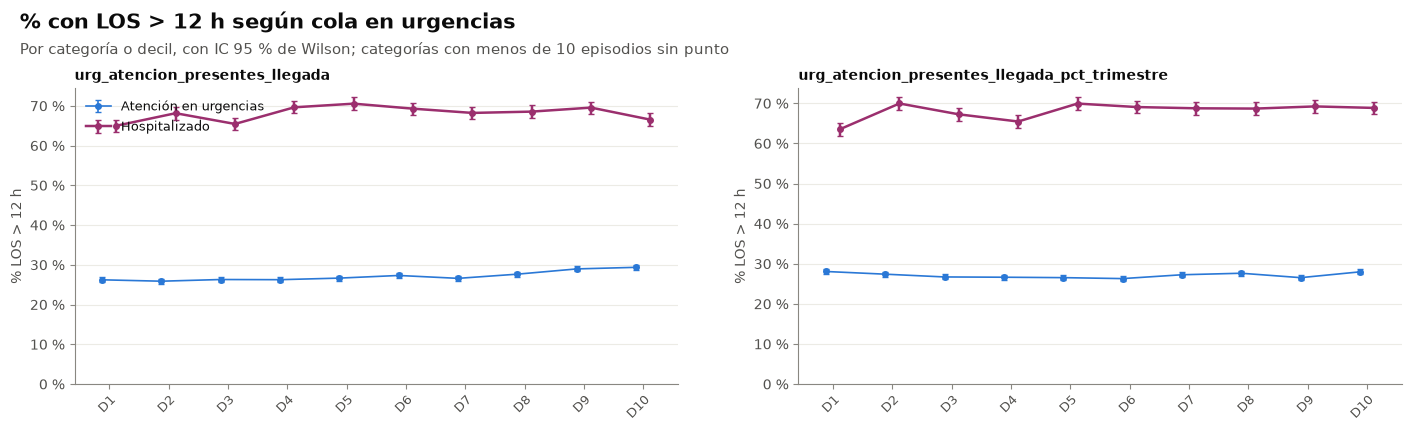

In [6]:
tablas.update(bv.mostrar_familia(episodios, 'cola en urgencias', '08_cola_urgencias'))

### 2.5 Ocupación del piso

**piso_censo_llegada: % con LOS > 12 h y LOS por categoría y grupo**

desde hasta       n n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h mediana_h p25_h  p75_h
grupo                categoria                                                                                               
2_atencion_urgencias D1          108   160  20.034     4.828        24,1           23,5           24,7      5,95  0,47  11,65
                     D2          160   167  18.831     4.788        25,4           24,8           26,1      6,04  0,40  12,14
                     D3          167   172  18.686     4.815        25,8           25,1           26,4      6,24  0,47  12,26
                     D4          172   177  21.506     5.679        26,4           25,8           27,0      6,35  0,36  12,47
                     D5          177   181  16.689     4.365        26,1           25,5           26,8      6,31  0,38  12,37
                     D6          181   186  20.100     5.345        26,6           26,0           27,2      6,88  0,49  12,62
                     D7          186   190  15.678     4.241        27,1           26,4           27,8      6,89  0,49  12,75
                     D8          190   195  18.587     5.249        28,2           27,6           28,9      7,19  0,50  13,23
                     D9          195   202  20.359     6.059        29,8           29,1           30,4      7,49  0,57  13,66
                     D10         202   228  16.750     5.374        32,1           31,4           32,8      7,97  0,54  14,68
3_hospitalizado      D1          113   159   3.370     2.261        67,1           65,5           68,7     22,57  8,05  38,40
                     D2          159   167   3.738     2.559        68,5           67,0           69,9     23,53  8,51  42,90
                     D3          167   172   3.394     2.310        68,1           66,5           69,6     22,91  8,71  42,84
                     D4          172   176   3.159     2.191        69,4           67,7           70,9     25,43  8,85  40,72
                     D5          176   181   3.680     2.509        68,2           66,7           69,7     23,71  8,94  41,83
                     D6          181   185   2.841     1.961        69,0           67,3           70,7     25,39  9,33  44,72
                     D7          185   190   3.345     2.224        66,5           64,9           68,1     22,45  8,46  45,27
                     D8          190   195   3.326     2.225        66,9           65,3           68,5     24,21  8,06  44,20
                     D9          195   201   3.383     2.273        67,2           65,6           68,8     25,87  8,80  47,73
                     D10         201   228   3.319     2.330        70,2           68,6           71,7     26,13  9,73  50,96

**piso_censo_llegada_pct_trimestre: % con LOS > 12 h y LOS por categoría y grupo**

desde  hasta       n n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h mediana_h p25_h  p75_h
grupo                categoria                                                                                                 
2_atencion_urgencias D1             0  10,82  18.791     4.749        25,3           24,7           25,9      6,11  0,45  12,09
                     D2         10,82  21,97  18.881     4.835        25,6           25,0           26,2      6,41  0,44  12,23
                     D3         21,97  32,41  18.823     4.985        26,5           25,9           27,1      6,62  0,44  12,52
                     D4         32,41  43,01  18.449     4.978        27,0           26,4           27,6      6,60  0,49  12,67
                     D5         43,01  53,95  18.972     5.114        27,0           26,3           27,6      6,59  0,42  12,67
                     D6         53,95  64,10  18.515     5.153        27,8           27,2           28,5      6,82  0,46  13,03
                     D7         64,10  73,38  19.313     5.417        28,1           27,4           28,7      6,98  0,48  13,14
                     D8         73,38  82,92  18.291     5.045        27,6           26,9           28,2      6,69  0,47  12,96
                     D9         82,92  92,12  18.935     5.445        28,8           28,1           29,4      7,09  0,47  13,33
                     D10        92,12    100  18.250     5.022        27,5           26,9           28,2      7,20  0,43  12,85
3_hospitalizado      D1             0  10,88   3.357     2.196        65,4           63,8           67,0     21,57  7,18  42,73
                     D2         10,88  21,83   3.393     2.263        66,7           65,1           68,3     23,10  8,04  41,52
                     D3         21,83  32,07   3.328     2.297        69,0           67,4           70,6     24,22  9,16  44,85
                     D4         32,07  42,90   3.433     2.246        65,4           63,8           67,0     22,07  7,55  43,59
                     D5         42,90  52,81   3.330     2.207        66,3           64,7           67,9     22,46  8,48  41,29
                     D6         52,81  63,45   3.341     2.260        67,6           66,0           69,2     24,04  8,70  44,79
                     D7         63,45  72,57   3.368     2.357        70,0           68,4           71,5     26,37  9,32  43,09
                     D8         72,57  82,65   3.321     2.315        69,7           68,1           71,2     25,56  9,39  49,07
                     D9         82,65  91,57   3.359     2.349        69,9           68,4           71,5     26,94  9,91  46,40
                     D10        91,57    100   3.325     2.353        70,8           69,2           72,3     26,32  9,93  41,10

**piso_grupo_censo_llegada: % con LOS > 12 h y LOS por categoría y grupo**

desde hasta       n n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h mediana_h  p25_h  p75_h
grupo                categoria                                                                                                
2_atencion_urgencias D1           14    35  19.872     3.800        19,1           18,6           19,7      1,91   0,13   9,44
                     D2           35    43  18.897     3.543        18,8           18,2           19,3      1,41   0,13   9,39
                     D3           43   122  18.421     4.177        22,7           22,1           23,3      5,13   0,20  11,13
                     D4          122   131  17.862     5.160        28,9           28,2           29,6      7,22   1,29  13,41
                     D5          131   138  21.998     6.276        28,5           27,9           29,1      7,21   1,18  13,25
                     D6          138   143  17.678     4.994        28,2           27,6           28,9      7,31   1,14  12,99
                     D7          143   148  18.406     5.347        29,1           28,4           29,7      7,42   1,26  13,46
                     D8          148   153  17.618     5.331        30,3           29,6           30,9      7,92   1,98  13,91
                     D9          153   160  19.360     6.267        32,4           31,7           33,0      8,26   2,28  14,59
                     D10         160   181  17.108     5.848        34,2           33,5           34,9      8,80   2,70  15,35
3_hospitalizado      D1           14    36   3.471     1.904        54,9           53,2           56,5     14,08   6,02  29,86
                     D2           36    47   3.252     1.782        54,8           53,1           56,5     14,14   6,43  31,73
                     D3           47   125   3.432     2.343        68,3           66,7           69,8     23,46   8,83  38,11
                     D4          125   133   3.632     2.653        73,0           71,6           74,5     26,10  10,87  47,19
                     D5          133   138   3.257     2.341        71,9           70,3           73,4     26,17  10,33  44,48
                     D6          138   143   3.152     2.276        72,2           70,6           73,7     26,87  10,45  47,87
                     D7          143   148   3.399     2.430        71,5           70,0           73,0     28,54  10,14  51,46
                     D8          148   154   3.767     2.609        69,3           67,8           70,7     26,63   9,25  50,69
                     D9          154   160   3.061     2.209        72,2           70,5           73,7     28,17  10,63  53,90
                     D10         160   181   3.132     2.296        73,3           71,7           74,8     28,86  10,85  52,67

**piso_grupo_censo_llegada_pct_trimestre: % con LOS > 12 h y LOS por categoría y grupo**

desde  hasta       n n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h mediana_h p25_h  p75_h
grupo                categoria                                                                                                 
2_atencion_urgencias D1             0  11,46  18.859     4.780        25,4           24,7           26,0      6,30  0,44  12,13
                     D2         11,46  22,80  18.588     4.880        26,2           25,6           26,9      6,47  0,48  12,49
                     D3         22,80  33,15  18.911     4.916        26,0           25,4           26,6      6,46  0,40  12,34
                     D4         33,15  42,95  18.758     5.106        27,2           26,6           27,9      6,78  0,53  12,72
                     D5         42,95  54,03  18.816     5.205        27,7           27,0           28,3      6,80  0,48     13
                     D6         54,03  64,49  18.493     4.969        26,9           26,2           27,5      6,53  0,39  12,75
                     D7         64,49  74,08  18.829     5.261        27,9           27,3           28,6      6,88  0,56  13,06
                     D8         74,08  82,74  18.757     5.417        28,9           28,2           29,5      7,05  0,46  13,36
                     D9         82,74  91,58  18.610     5.094        27,4           26,7           28,0      6,97  0,43  12,78
                     D10        91,58    100  18.599     5.115        27,5           26,9           28,1      6,91  0,39  12,92
3_hospitalizado      D1             0  11,41   3.366     2.185        64,9           63,3           66,5     21,17  7,20  37,93
                     D2         11,41  22,25   3.380     2.355        69,7           68,1           71,2     24,29  9,28  43,33
                     D3         22,25  32,97   3.340     2.225        66,6           65,0           68,2     23,04  8,20  42,73
                     D4         32,97  42,82   3.350     2.248        67,1           65,5           68,7     24,38  7,96  45,70
                     D5         42,82  52,81   3.393     2.285        67,3           65,8           68,9     22,97  8,48  42,28
                     D6         52,81  63,92   3.324     2.244        67,5           65,9           69,1     23,99  8,43  42,44
                     D7         63,92     74   3.376     2.354        69,7           68,2           71,2     25,75  9,16  48,94
                     D8            74  82,19   3.373     2.339        69,3           67,8           70,9     25,64  9,47  49,15
                     D9         82,19  91,35   3.318     2.263        68,2           66,6           69,8     25,12  9,20  41,65
                     D10        91,35    100   3.335     2.345        70,3           68,7           71,8     25,53  9,86  42,30

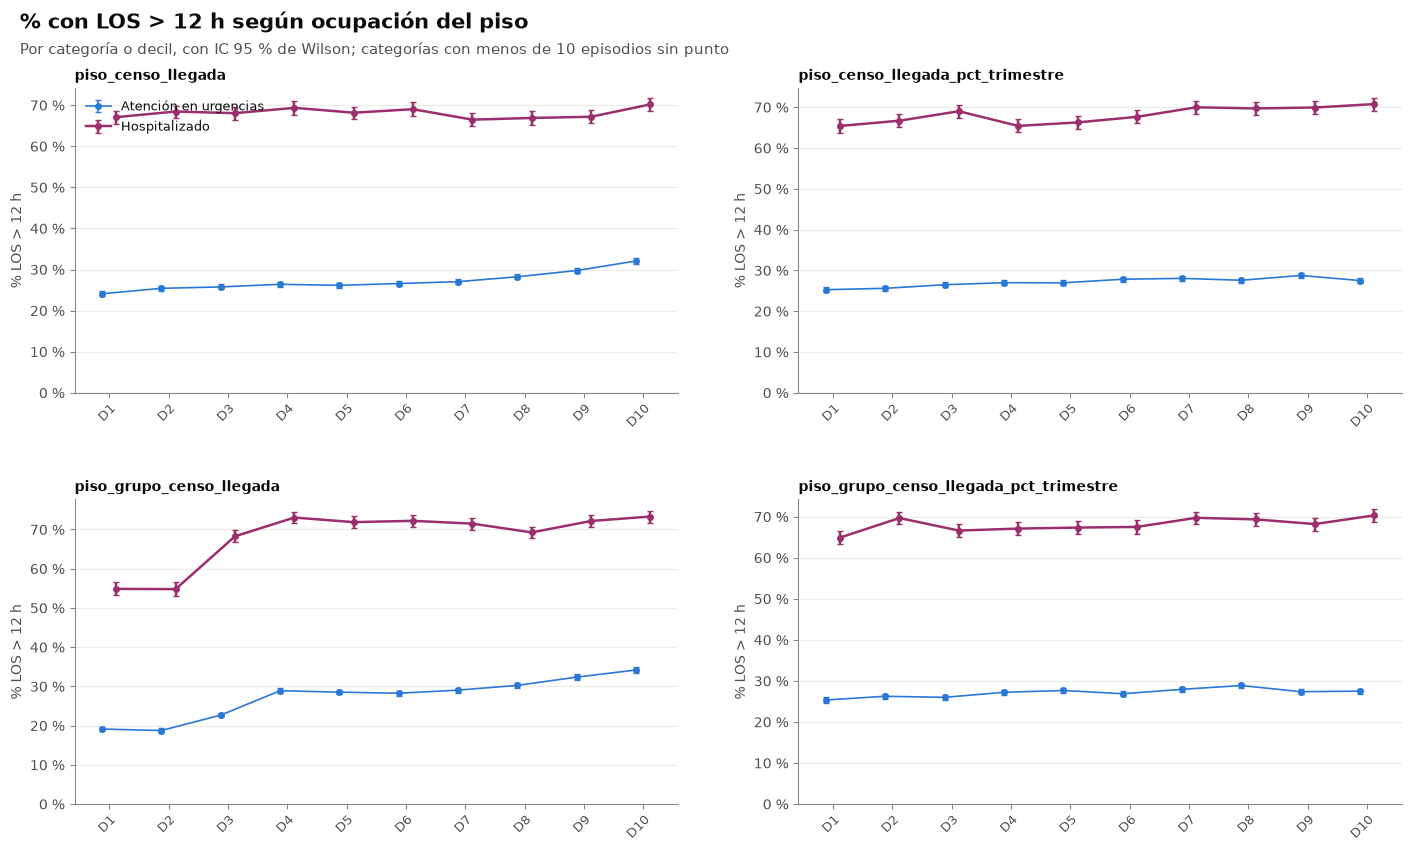

In [7]:
tablas.update(bv.mostrar_familia(episodios, 'ocupación del piso', '08_ocupacion_piso'))

### 2.6 LOS reciente

**los_reciente_promedio_h: % con LOS > 12 h y LOS por categoría y grupo**

desde   hasta       n n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h mediana_h p25_h  p75_h
grupo                categoria                                                                                                  
2_atencion_urgencias D1          0,19    6,46  18.725     4.949        26,4           25,8           27,1      6,37  0,28  12,61
                     D2          6,46    8,50  18.720     4.888        26,1           25,5           26,8      6,44  0,33  12,40
                     D3          8,50   10,16  18.719     4.960        26,5           25,9           27,1      6,69  0,42  12,47
                     D4         10,16   11,77  18.723     5.036        26,9           26,3           27,5      6,72  0,44  12,67
                     D5         11,77   13,32  18.720     5.069        27,1           26,4           27,7      6,72  0,49  12,66
                     D6         13,32   15,05  18.727     5.041        26,9           26,3           27,6      6,55  0,52  12,69
                     D7         15,05   17,23  18.718     5.002        26,7           26,1           27,4      6,64  0,54  12,67
                     D8         17,23   20,23  18.718     5.099        27,2           26,6           27,9      6,92  0,51  12,86
                     D9         20,23   25,41  18.722     5.241        28,0           27,4           28,6      6,97  0,56  13,08
                     D10        25,41  106,51  18.721     5.457        29,1           28,5           29,8      7,12  0,68  13,53
3_hospitalizado      D1          0,33    6,72   3.357     2.319        69,1           67,5           70,6     27,75  9,09  50,09
                     D2          6,72    8,75   3.354     2.330        69,5           67,9           71,0     27,14  9,67  47,70
                     D3          8,75   10,49   3.355     2.307        68,8           67,2           70,3     26,30  9,10  45,89
                     D4         10,49   12,09   3.355     2.367        70,5           69,0           72,1     25,26  9,84  46,11
                     D5         12,09   13,62   3.357     2.287        68,1           66,5           69,7     23,76  8,99  42,94
                     D6         13,62   15,44   3.354     2.299        68,5           67,0           70,1     23,91  8,54  45,58
                     D7         15,44   17,68   3.356     2.255        67,2           65,6           68,8     21,98  8,29  41,90
                     D8         17,68   20,68   3.354     2.263        67,5           65,9           69,0     22,05  8,26  41,60
                     D9         20,68   25,98   3.356     2.257        67,2           65,7           68,8     20,94  8,10  41,35
                     D10        25,98  106,51   3.355     2.157        64,3           62,7           65,9     19,14  7,60  39,67

**los_reciente_mediana_h: % con LOS > 12 h y LOS por categoría y grupo**

desde  hasta       n n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h mediana_h p25_h  p75_h
grupo                categoria                                                                                                 
2_atencion_urgencias D1          0,10   0,52  18.724     5.059        27,0           26,4           27,7      6,22  0,21  12,84
                     D2          0,52   1,82  18.720     5.093        27,2           26,6           27,9      6,46  0,32  12,98
                     D3          1,82   3,76  18.722     5.090        27,2           26,6           27,8      6,37  0,38  12,89
                     D4          3,76   5,43  18.725     5.022        26,8           26,2           27,5      6,31  0,42  12,59
                     D5          5,43   6,64  18.717     4.669        24,9           24,3           25,6      6,29  0,45  11,98
                     D6          6,64   7,73  18.722     4.754        25,4           24,8           26,0      6,50  0,53  12,13
                     D7          7,73   8,86  18.730     5.111        27,3           26,6           27,9      6,94  0,57  12,85
                     D8          8,86  10,17  18.712     5.108        27,3           26,7           27,9      7,01  0,66  12,75
                     D9         10,17  12,07  18.728     5.565        29,7           29,1           30,4      7,52  0,78  13,51
                     D10        12,07  79,68  18.713     5.271        28,2           27,5           28,8      7,47  0,83  13,01
3_hospitalizado      D1          0,10   0,67   3.366     2.313        68,7           67,1           70,3     27,14  9,12  50,55
                     D2          0,67   2,21   3.346     2.304        68,9           67,3           70,4     27,06  9,28  50,01
                     D3          2,21   4,32   3.354     2.340        69,8           68,2           71,3     26,31  9,14  48,81
                     D4          4,32   5,90   3.356     2.244        66,9           65,2           68,4     24,05  8,19  45,21
                     D5          5,90   7,06   3.356     2.250        67,0           65,4           68,6     22,84  8,10  42,91
                     D6          7,06   8,08   3.355     2.235        66,6           65,0           68,2     21,63  8,34  43,59
                     D7          8,08   9,14   3.354     2.246        67,0           65,3           68,5     21,68  7,88  41,78
                     D8          9,14  10,47   3.356     2.291        68,3           66,7           69,8     20,54  8,76  39,49
                     D9         10,47  12,24   3.355     2.276        67,8           66,2           69,4     19,50  8,86  38,62
                     D10        12,24  60,22   3.355     2.342        69,8           68,2           71,3     22,72  9,44  40,76

**n_salidas_recientes: % con LOS > 12 h y LOS por categoría y grupo**

desde hasta       n n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h mediana_h p25_h  p75_h
grupo                categoria                                                                                               
2_atencion_urgencias D1            0    33  20.780     5.829        28,1           27,4           28,7      7,38  0,81  13,08
                     D2           33    40  19.095     5.352        28,0           27,4           28,7      7,16  0,67  13,14
                     D3           40    46  19.637     5.412        27,6           26,9           28,2      6,86  0,45  12,89
                     D4           46    51  17.848     4.968        27,8           27,2           28,5      7,13  0,51  12,94
                     D5           51    56  17.489     4.750        27,2           26,5           27,8      6,91  0,43  12,72
                     D6           56    62  18.782     5.288        28,1           27,5           28,8      6,83  0,38  13,12
                     D7           62    69  18.562     5.060        27,3           26,6           27,9      6,56  0,36  12,81
                     D8           69    78  19.282     5.069        26,3           25,7           26,9      6,29  0,35  12,46
                     D9           78    90  17.509     4.540        25,9           25,3           26,6      6,02  0,37  12,37
                     D10          90   164  18.236     4.475        24,5           23,9           25,2      5,74  0,42  11,81
3_hospitalizado      D1            0    32   3.421     2.295        67,1           65,5           68,6     25,44  8,54  48,70
                     D2           32    39   3.332     2.282        68,5           66,9           70,0     27,15  9,61  44,74
                     D3           39    45   3.564     2.467        69,2           67,7           70,7     27,51  9,56  47,42
                     D4           45    51   3.787     2.611        69,0           67,5           70,4     25,20  9,33  46,73
                     D5           51    56   3.072     2.111        68,7           67,1           70,3     26,27  9,15  42,14
                     D6           56    62   3.422     2.382        69,6           68,0           71,1     24,83  9,25  46,62
                     D7           62    69   3.131     2.148        68,6           67,0           70,2     24,03  8,78  45,35
                     D8           69    78   3.387     2.282        67,4           65,8           68,9     23,46  8,25  44,88
                     D9           78    91   3.260     2.167        66,5           64,8           68,1     22,02  7,36  41,83
                     D10          91   156   3.179     2.098        66,0           64,3           67,6     20,54  6,47  41,06

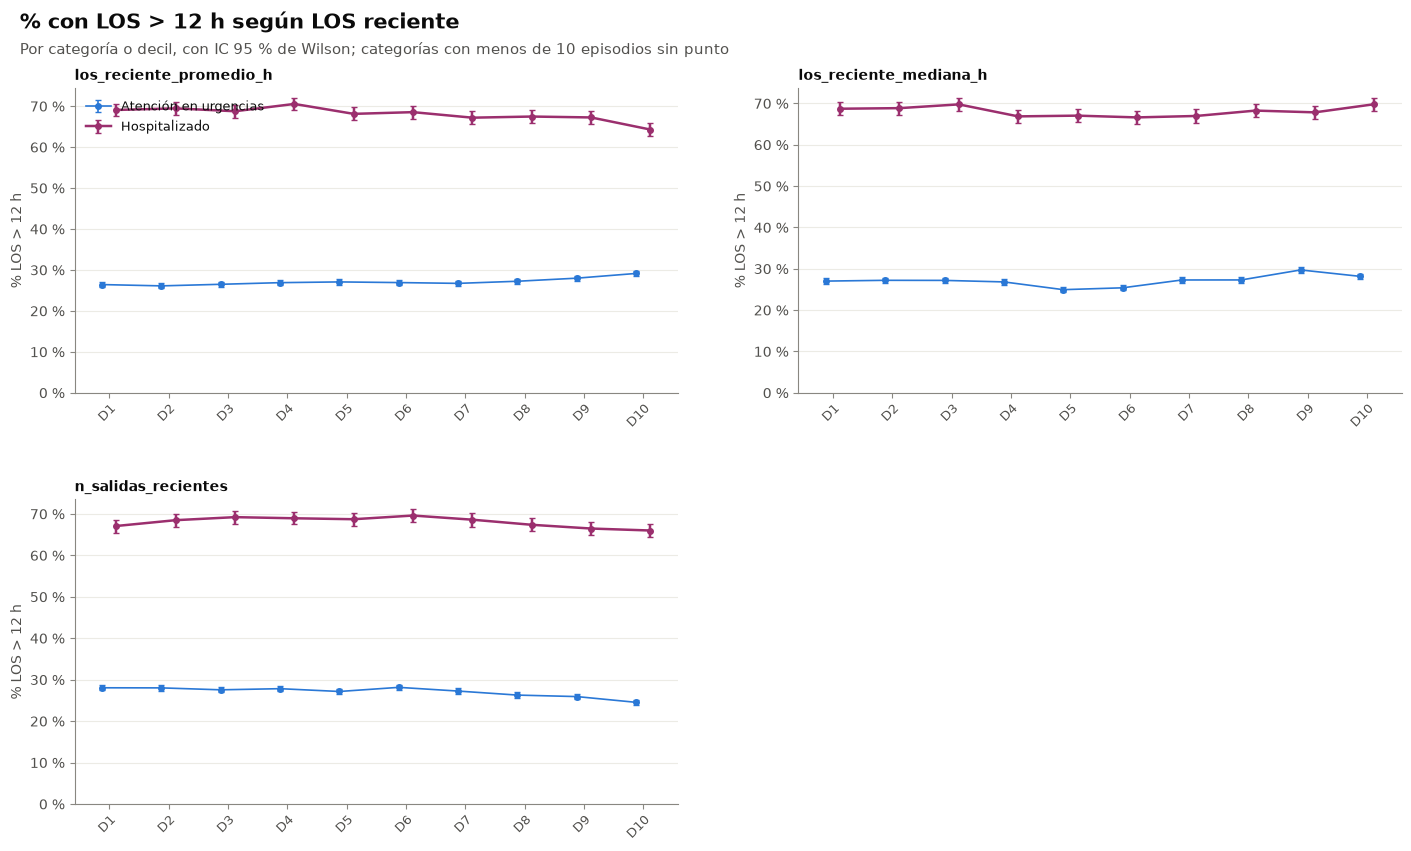

In [8]:
tablas.update(bv.mostrar_familia(episodios, 'LOS reciente', '08_los_reciente'))

## 3. Tamaño de efecto

Por variable y grupo: diferencia entre la categoría con mayor y menor % > 12 h (solo categorías con al menos 10 episodios), V de Cramér entre la categoría y LOS > 12 h y, para las continuas, correlación de Spearman con el LOS en horas. La tabla y el gráfico se ordenan por V de Cramér; el gráfico no incluye las versiones absolutas de la ocupación ni las versiones redundantes de la edad (edad en años y pediatría).

In [9]:
efectos = pd.concat([bv.efecto_variable(episodios, variable, tabla) for variable, tabla in tablas.items()],
                    ignore_index=True)
familia_de = {v: familia for familia, variables in bv.FAMILIAS.items() for v in variables}
efectos.insert(2, 'familia', efectos['variable'].map(familia_de))
efectos = efectos.sort_values(['grupo', 'v_cramer'], ascending=[True, False])
mostrar_tabla(suprimir_pequenos(efectos.set_index(['grupo', 'variable']).round(3), ['n']),
              'Tamaño de efecto por variable y grupo')

**Tamaño de efecto por variable y grupo**

familia        n diferencia_max_pp v_cramer spearman
grupo                variable                                                                                                     
2_atencion_urgencias edad_llegada                                            paciente  187.220             23,63    0,143     0,23
                     grupo_edad                                              paciente  187.220             26,40    0,140      NaN
                     piso_grupo_censo_llegada                      ocupación del piso  187.220             15,43    0,113     0,19
                     pediatria                                               paciente  187.220             10,83    0,106      NaN
                     hora                                                  calendario  187.220             16,89    0,071      NaN
                     anio                                                  calendario  187.220              6,61    0,063      NaN
                     franja                                                calendario  187.220             10,63    0,060      NaN
                     piso_censo_llegada                            ocupación del piso  187.220              7,99    0,049     0,05
                     n_episodios_previos_30d                          historia previa  187.220              6,03    0,048      NaN
                     n_episodios_previos_365d                         historia previa  131.575              3,78    0,040      NaN
                     los_reciente_mediana_h                              LOS reciente  187.213              4,77    0,028     0,04
                     urg_atencion_presentes_llegada                 cola en urgencias  187.220              3,49    0,026     0,01
                     n_salidas_recientes                                 LOS reciente  187.220              3,62    0,025    -0,04
                     piso_censo_llegada_pct_trimestre              ocupación del piso  187.220              3,48    0,023     0,02
                     piso_grupo_censo_llegada_pct_trimestre        ocupación del piso  187.220              3,53    0,022     0,01
                     mes                                                   calendario  187.220              2,70    0,021      NaN
                     los_reciente_promedio_h                             LOS reciente  187.213              3,04    0,019     0,03
                     dia_semana                                            calendario  187.220              2,55    0,019      NaN
                     urg_atencion_presentes_llegada_pct_trimestre   cola en urgencias  187.220              1,77    0,014    -0,02
                     festivo                                               calendario  187.220              2,87    0,013      NaN
                     fin_de_semana                                         calendario  187.220              1,11    0,011      NaN
                     hosp_previa_30d                                  historia previa  187.220              2,23    0,006      NaN
                     sexo                                                    paciente  187.220              0,15    0,002      NaN
3_hospitalizado      grupo_edad                                              paciente   33.555             39,83    0,185      NaN
                     edad_llegada                                            paciente   33.555             29,99    0,178     0,15
                     pediatria                                               paciente   33.555             17,34    0,154      NaN
                     piso_grupo_censo_llegada                      ocupación del piso   33.555             18,51    0,146     0,13
                     hora                                                  calendario   33.555             16,72    0,080      NaN
                     franja                                                calendario   33.555             10,11    0,065      NaN
                 

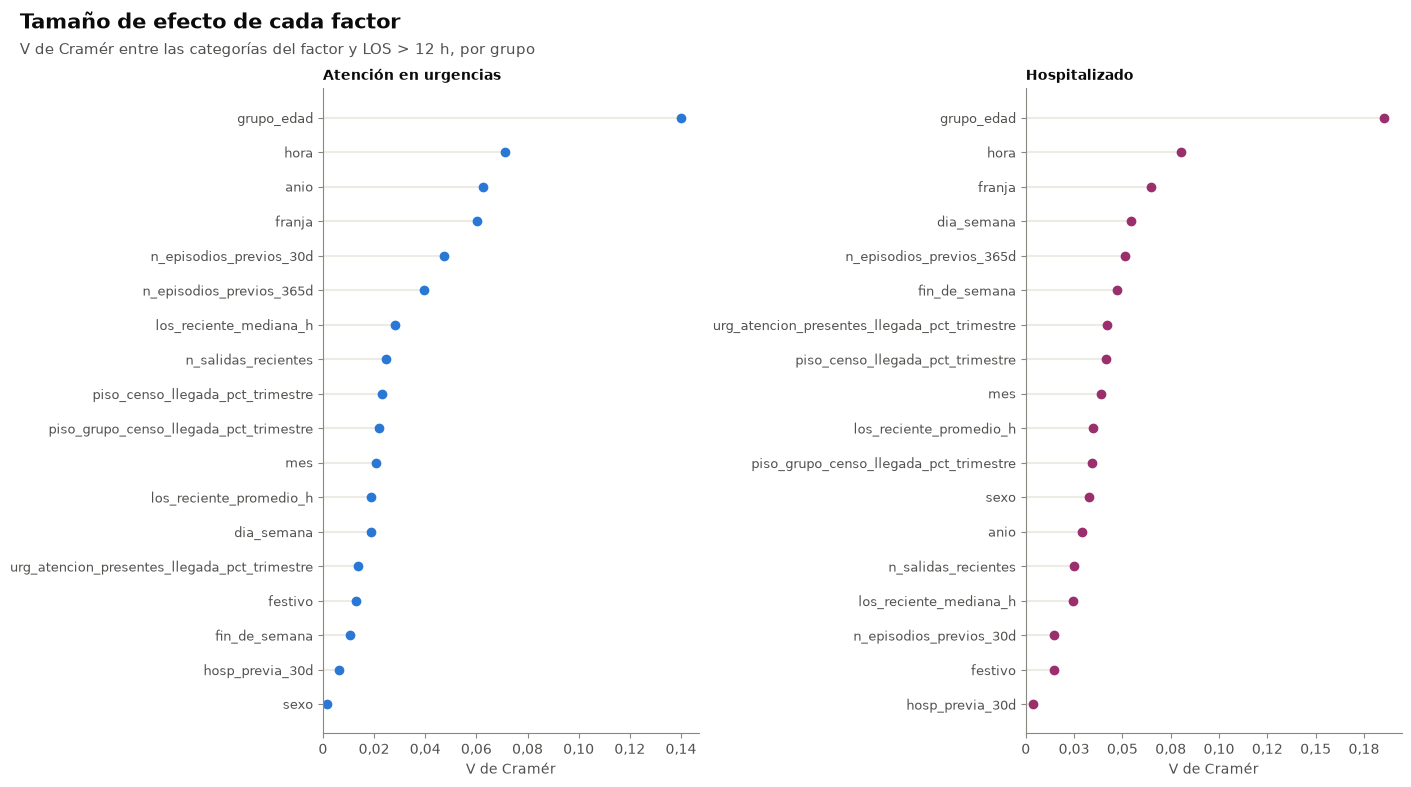

In [10]:
fig = bv.grafico_efecto(efectos)
titulo_hallazgo(fig, 'Tamaño de efecto de cada factor',
                f'V de Cramér entre las categorías del factor y LOS > {config.UMBRAL_OPERATIVO_H} h, por grupo')
guardar_figura(fig, '08_tamano_efecto')
plt.show()

## 4. Tendencia temporal

% con LOS > 12 h, mediana del LOS y número de llegadas por trimestre de llegada, para cada grupo.

**Estancia y llegadas por trimestre y grupo**

n n_mas_12h pct_mas_12h ic_inf_mas_12h ic_sup_mas_12h mediana_h p25_h  p75_h
grupo                trimestre                                                                                   
2_atencion_urgencias 2023Q1     10.007     2.449        24,5           23,6           25,3      5,74  0,47  11,77
                     2023Q2     15.370     3.874        25,2           24,5           25,9      5,91  0,35  12,07
                     2023Q3     15.520     3.790        24,4           23,8           25,1      6,35  0,52  11,79
                     2023Q4     14.748     3.593        24,4           23,7           25,1      6,22  0,50  11,77
                     2024Q1     15.165     3.902        25,7           25,0           26,4      5,84  0,33  12,26
                     2024Q2     16.457     4.117        25,0           24,4           25,7      5,79  0,23     12
                     2024Q3     15.826     3.608        22,8           22,1           23,5      6,35  0,33  11,26
                     2024Q4     14.464     4.019        27,8           27,1           28,5      7,02  0,63  13,09
                     2025Q1     14.547     4.287        29,5           28,7           30,2      7,68  1,25  13,59
                     2025Q2     15.009     4.817        32,1           31,4           32,9      8,14  0,98  14,67
                     2025Q3     14.995     4.649        31,0           30,3           31,8      7,78  0,39  14,20
                     2025Q4     13.232     3.927        29,7           28,9           30,5      7,32  0,32  13,77
                     2026Q1     11.880     3.711        31,2           30,4           32,1      7,59  0,81  14,62
3_hospitalizado      2023Q1      1.845     1.308        70,9           68,8           72,9     23,61  9,34  39,62
                     2023Q2      2.960     2.091        70,6           69,0           72,2     24,79  9,68  37,89
                     2023Q3      2.871     2.012        70,1           68,4           71,7     24,92  9,58  39,90
                     2023Q4      2.742     1.856        67,7           65,9           69,4     24,06  8,63  40,78
                     2024Q1      2.603     1.733        66,6           64,7           68,4     22,99  7,75  44,55
                     2024Q2      2.688     1.878        69,9           68,1           71,6     23,55  9,43  37,56
                     2024Q3      2.855     1.962        68,7           67,0           70,4     23,66  8,80  40,20
                     2024Q4      2.459     1.670        67,9           66,0           69,7     26,21  8,76  47,58
                     2025Q1      2.444     1.702        69,6           67,8           71,4     26,08  8,81  51,47
                     2025Q2      2.454     1.632        66,5           64,6           68,3     23,46  8,48  46,39
                     2025Q3      2.796     1.853        66,3           64,5           68,0     22,44  8,50  46,95
                     2025Q4      2.520     1.608        63,8           61,9           65,7     21,54  7,23  44,58
                     2026Q1      2.318     1.538        66,3           64,4           68,2     23,26  8,59  52,84

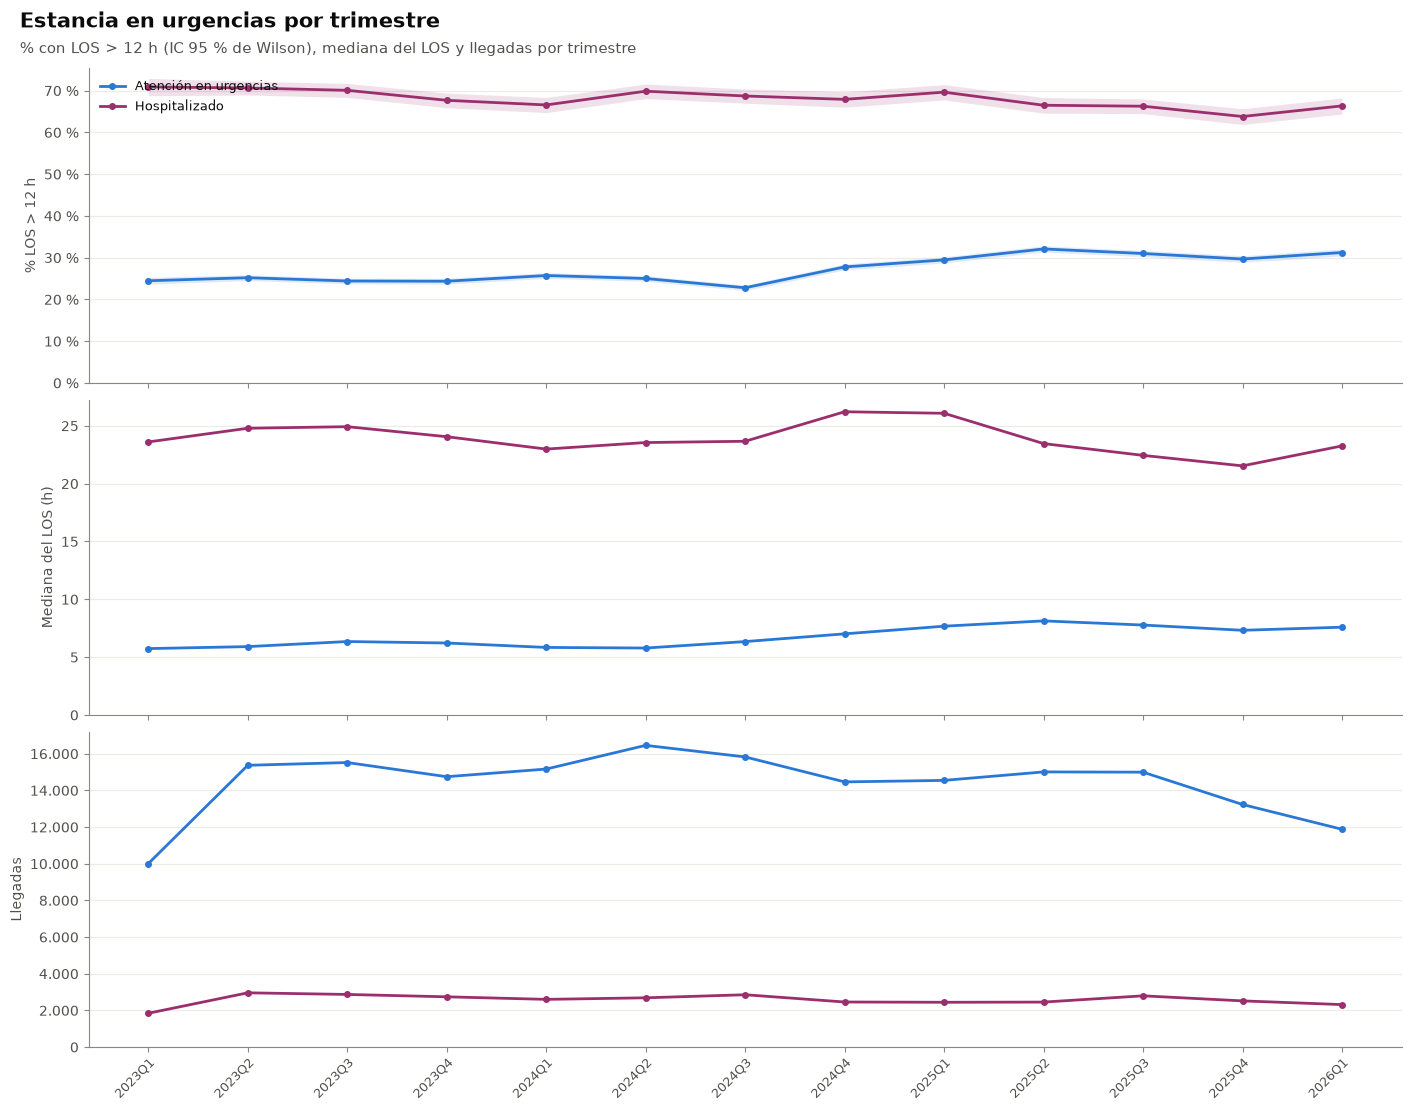

In [11]:
tendencia = bv.tendencia_trimestral(episodios)
mostrar_tabla(bv.tabla_segura_bivariado(tendencia), 'Estancia y llegadas por trimestre y grupo')

fig = bv.grafico_tendencia(tendencia)
titulo_hallazgo(fig, 'Estancia en urgencias por trimestre',
                f'% con LOS > {config.UMBRAL_OPERATIVO_H} h (IC 95 % de Wilson), mediana del LOS y llegadas por trimestre')
guardar_figura(fig, '08_tendencia_trimestral')
plt.show()

## Exportación

Tablas agregadas en `data/processed/`; los conteos menores a 10 se suprimen.

In [12]:
config.DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
bivariado = bv.tabla_exportacion(tablas)
bivariado.to_csv(config.DATA_PROCESSED / 'factores_bivariado.csv', index=False)
efecto_csv = suprimir_pequenos(efectos.round(4), ['n'], columnas_derivadas=['diferencia_max_pp', 'v_cramer', 'spearman'])
efecto_csv.to_csv(config.DATA_PROCESSED / 'factores_efecto.csv', index=False)
mostrar_tabla(pd.DataFrame({'filas': {'factores_bivariado.csv': len(bivariado), 'factores_efecto.csv': len(efecto_csv)},
                            'columnas': {'factores_bivariado.csv': bivariado.shape[1],
                                         'factores_efecto.csv': efecto_csv.shape[1]}}).rename_axis('archivo'),
              'Archivos exportados en data/processed/')

**Archivos exportados en data/processed/**

,filas,columnas
archivo,,
factores_bivariado.csv,353,13
factores_efecto.csv,46,7
